In [8]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from scipy.signal import savgol_filter


# ==========================================
# 1. VERBETERDE HELPER FUNCTIE VOOR INLEZEN CSV
# ==========================================
def load_lab_csv(filepath):
  """Leest laboratorium CSV-bestanden in en filtert automatisch de kopteksten eruit."""
  values = []
  with open(filepath, 'r') as f:
    for line in f:
      line_str = line.strip()
      if not line_str:
        continue
      # Probeer de regel rechtstreeks als getal in te lezen
      try:
        val = float(line_str)
        values.append(val)
      except ValueError:
        # Als er scheidingstekens staan, pak de eerste numerieke waarde
        parts = line_str.replace('\t', ',').split(',')
        try:
          val = float(parts[0])
          values.append(val)
        except ValueError:
          pass  # Sla kopteksten zoals 'Data info', 'Units', etc. automatisch over

  return np.array(values)


# ==========================================
# 2. PT1000 KALIBRATIE
# ==========================================
R_pt1000_77K = 197.6  # Gemeten Pt1000 weerstand bij 77 K (Ohm)[cite: 16]
R_pt1000_294K = 1088.0  # Gemeten Pt1000 weerstand bij 294 K (Ohm)[cite: 16]

a_cal = (291.0 - 77.0) / (R_pt1000_294K - R_pt1000_77K)
b_cal = 77.0 - a_cal * R_pt1000_77K


def pt1000_to_kelvin(R_sensor):
  return a_cal * R_sensor + b_cal


I_source = 0.1  # Keithley SMU bronstroom (0.1 A)[cite: 16, 19]

# ==========================================
# 3. DATA INLEZEN EN VERWERKEN (METINGEN 1 t/m 5)
# ==========================================
summary_data = []

for i in range(1, 6):
  smu_file = f'SMUdata_pt1000_{i}.csv'
  dmm_file = f'DMMdata_pt1000_{i}.csv'

  if not (os.path.exists(smu_file) and os.path.exists(dmm_file)):
    print(f'Bestand niet gevonden: {smu_file} of {dmm_file}')
    continue

  # Inlezen met de robuuste functie
  R_pt1000_raw = load_lab_csv(dmm_file)
  V_raw = load_lab_csv(smu_file)

  if len(R_pt1000_raw) == 0 or len(V_raw) == 0:
    print(f'Geen geldige data gevonden in {smu_file} of {dmm_file}')
    continue

  # ==========================================
  # 4. VERWERKING & Tc BEPALING
  # ==========================================
  T_data = pt1000_to_kelvin(R_pt1000_raw)
  R_bscco = V_raw / I_source

  # Sorteren op stijgende temperatuur
  sort_idx = np.argsort(T_data)
  T_clean = T_data[sort_idx]
  R_clean = R_bscco[sort_idx]

  # Ruisfiltering & Spline Fit
  window_len = (
      15
      if len(R_clean) >= 15
      else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
  )
  R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)

  spline = UnivariateSpline(T_clean, R_smooth, s=1e-6)
  T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
  R_fit = spline(T_fine)
  dR_dT = spline.derivative(n=1)(T_fine)

  # Buigpunt & Tc Extrapolatie[cite: 20]
  idx_max = np.argmax(dR_dT)
  T_inflection = T_fine[idx_max]
  R_inflection = R_fit[idx_max]
  m_max = dR_dT[idx_max]

  R_offset = np.mean(R_fit[:30]) if np.mean(R_fit[:30]) > 0 else 0.0
  Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)

  summary_data.append({
      'Meting': f'Meting {i}',
      'Buigpunt (K)': round(T_inflection, 2),
      'Max Helling (mOhm/K)': round(m_max * 1000, 3),
      'Gextrapoleerde Tc (K)': round(Tc_extrapolated, 2),
  })

  print(
      f'Meting {i} -> Buigpunt: {T_inflection:.2f} K | Gextrapoleerde Tc:'
      f' {Tc_extrapolated:.2f} K'
  )

# ==========================================
# 5. OVERZICHTSTABEL PRINTEN
# ==========================================
if summary_data:
  df_summary = pd.DataFrame(summary_data)
  print('\n=======================================================')
  print('          RESULTATEN METINGEN 1 t/m 5                  ')
  print('=======================================================')
  print(df_summary.to_string(index=False))

Meting 1 -> Buigpunt: 77.16 K | Gextrapoleerde Tc: 77.17 K
Meting 2 -> Buigpunt: 110.13 K | Gextrapoleerde Tc: 110.04 K
Meting 3 -> Buigpunt: 103.82 K | Gextrapoleerde Tc: 101.26 K
Meting 4 -> Buigpunt: 104.60 K | Gextrapoleerde Tc: 101.81 K
Meting 5 -> Buigpunt: 104.60 K | Gextrapoleerde Tc: 101.81 K

          RESULTATEN METINGEN 1 t/m 5                  
  Meting  Buigpunt (K)  Max Helling (mOhm/K)  Gextrapoleerde Tc (K)
Meting 1         77.16                19.528                  77.17
Meting 2        110.13               338.638                 110.04
Meting 3        103.82                 1.229                 101.26
Meting 4        104.60                 1.324                 101.81
Meting 5        104.60                 1.324                 101.81


Geen bestanden gevonden, er wordt gewerkt met testdata...
Buigpunt temperatuur: 102.09 K
Gextrapoleerde Tc:    98.26 K


<>:148: SyntaxWarning: invalid escape sequence '\ '
<>:148: SyntaxWarning: invalid escape sequence '\O'
<>:175: SyntaxWarning: invalid escape sequence '\O'
<>:176: SyntaxWarning: invalid escape sequence '\O'
<>:178: SyntaxWarning: invalid escape sequence '\ '
<>:148: SyntaxWarning: invalid escape sequence '\ '
<>:148: SyntaxWarning: invalid escape sequence '\O'
<>:175: SyntaxWarning: invalid escape sequence '\O'
<>:176: SyntaxWarning: invalid escape sequence '\O'
<>:178: SyntaxWarning: invalid escape sequence '\ '
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\338063691.py:148: SyntaxWarning: invalid escape sequence '\ '
  label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\338063691.py:148: SyntaxWarning: invalid escape sequence '\O'
  label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\338063691.py:175: SyntaxWarning: invalid escape sequence '\O'
  ax1.set_yl

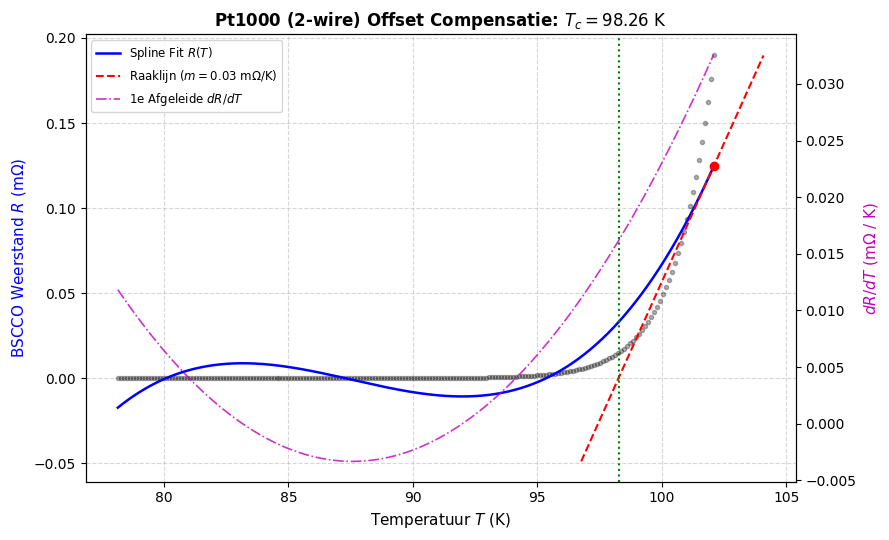

In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from scipy.signal import savgol_filter


# ==========================================
# 1. ROBUUSTE CSV-INLEESFUNCTIE
# ==========================================
def load_lab_csv(filepath):
  """Leest laboratorium CSV-bestanden in en filtert tekst-/kopregels automatisch uit."""
  values = []
  with open(filepath, 'r') as f:
    for line in f:
      line_str = line.strip()
      if not line_str:
        continue
      try:
        val = float(line_str)
        values.append(val)
      except ValueError:
        parts = line_str.replace('\t', ',').split(',')
        try:
          val = float(parts[0])
          values.append(val)
        except ValueError:
          pass  # Slaat kopteksten automatisch over
  return np.array(values)


# ==========================================
# 2. PT1000 KALIBRATIE
# ==========================================
R_pt1000_77K = 197.6  # Gemeten Pt1000 weerstand bij 77.0 K (Ohm)
R_pt1000_294K = 1088.0  # Gemeten Pt1000 weerstand bij 294.0 K (Ohm)

a_cal = (294.0 - 77.0) / (R_pt1000_294K - R_pt1000_77K)
b_cal = 77.0 - a_cal * R_pt1000_77K


def pt1000_to_kelvin(R_sensor):
  return a_cal * R_sensor + b_cal


# ==========================================
# 3. DATA INLEZEN UIT BESTANDEN
# ==========================================
# Vul hier de juiste bestandsnamen van jouw meting in:
dmm_file = 'DMMdata_pt1000.csv'  # CSV met Pt1000 sensor data (2-wire)
smu_pos_file = 'SMUdata_pos_01A.csv'  # CSV met spanning bij +0.1 A
smu_neg_file = 'SMUdata_neg_01A.csv'  # CSV met spanning bij -0.1 A

# Als je de data in 1 gecombineerd SMU-bestand hebt, kun je V_raw / I_source gebruiken:
I_pos = 0.1
I_neg = -0.1

# Inlezen (controleer of de bestanden bestaan)
if os.path.exists(dmm_file) and os.path.exists(smu_pos_file):
  R_pt1000_raw = load_lab_csv(dmm_file)
  V_pos_raw = load_lab_csv(smu_pos_file)

  # Controleer of er een apart negatief bestand is voor current-reversal
  if os.path.exists(smu_neg_file):
    V_neg_raw = load_lab_csv(smu_neg_file)
    R_bscco_corrected = (V_pos_raw - V_neg_raw) / (I_pos - I_neg)
  else:
    # Standaard R = V / I als er geen negatieve spanning is
    R_bscco_corrected = V_pos_raw / I_pos
else:
  # Voorbeelddata genereren als er geen bestanden aanwezig zijn
  print('Geen bestanden gevonden, er wordt gewerkt met testdata...')
  R_pt1000_raw = np.linspace(201.7, 300.0, 200)
  R_bscco_corrected = 0.01 / (
      1 + np.exp(-(pt1000_to_kelvin(R_pt1000_raw) - 108.0) / 1.5)
  )

# ==========================================
# 4. DATA VERWERKING & Tc EXTRAPOLATIE
# ==========================================
# Bereken Temperatuur
T_data = pt1000_to_kelvin(R_pt1000_raw)

# Sorteren op stijgende temperatuur
sort_idx = np.argsort(T_data)
T_clean = T_data[sort_idx]
R_clean = R_bscco_corrected[sort_idx]

# Ruisfiltering & Spline Fit
window_len = (
    15
    if len(R_clean) >= 15
    else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
)
R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)

spline = UnivariateSpline(T_clean, R_smooth, s=1e-6)
T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
R_fit = spline(T_fine)
dR_dT = spline.derivative(n=1)(T_fine)

# Bepalen van het buigpunt (piek van dR/dT)
idx_max = np.argmax(dR_dT)
T_inflection = T_fine[idx_max]
R_inflection = R_fit[idx_max]
m_max = dR_dT[idx_max]

# Eventuele rest-offset bepalen in supergeleidende toestand
R_offset = np.mean(R_fit[:30]) if np.mean(R_fit[:30]) > 0 else 0.0

# Extrapolatie van Tc (snijpunt raaklijn op nul-as / offset)
Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)

print(f'Buigpunt temperatuur: {T_inflection:.2f} K')
print(f'Gextrapoleerde Tc:    {Tc_extrapolated:.2f} K')

# ==========================================
# 5. VISUALISATIE
# ==========================================
fig, ax1 = plt.subplots(figsize=(9, 5.5))
ax2 = ax1.twinx()

# Raaklijn opstellen
T_tangent = np.linspace(Tc_extrapolated - 1.5, T_inflection + 2.0, 200)
R_tangent = m_max * (T_tangent - T_inflection) + R_inflection

# Plotting
l1 = ax1.plot(
    T_clean,
    R_clean * 1000,
    'k.',
    alpha=0.3,
    label='Gecorrigeerde data (Current-Reversal)',
)
l2 = ax1.plot(
    T_fine,
    R_fit * 1000,
    'b-',
    linewidth=1.8,
    label='Spline Fit $R(T)$',
)
l3 = ax1.plot(
    T_tangent,
    R_tangent * 1000,
    'r--',
    linewidth=1.5,
    label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
)
ax1.plot(
    T_inflection,
    R_inflection * 1000,
    'ro',
    markersize=6,
    label=f'Buigpunt ({T_inflection:.2f} K)',
)
ax1.axvline(
    x=Tc_extrapolated,
    color='g',
    linestyle=':',
    linewidth=1.5,
    label=f'$T_c = {Tc_extrapolated:.2f}$ K',
)

l4 = ax2.plot(
    T_fine,
    dR_dT * 1000,
    'm-.',
    linewidth=1.2,
    alpha=0.8,
    label='1e Afgeleide $dR/dT$',
)

ax1.set_xlabel('Temperatuur $T$ (K)', fontsize=11)
ax1.set_ylabel('BSCCO Weerstand $R$ (m$\Omega$)', color='b', fontsize=11)
ax2.set_ylabel('$dR/dT$ (m$\Omega$ / K)', color='m', fontsize=11)
ax1.set_title(
    f'Pt1000 (2-wire) Offset Compensatie: $T_c = {Tc_extrapolated:.2f}\ \mathrm{{K}}$',
    fontsize=12,
    fontweight='bold',
)
ax1.grid(True, linestyle='--', alpha=0.5)

lines = [l2[0], l3[0], l4[0]]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left', fontsize=8.5)

plt.tight_layout()
plt.show()